Programming Assignment 2: Classification Task and Performance Evaluation
========================

Ethan Ciavolella

Data Mining I

2026/10/30

Dataset
-----------

The dataset I chose is the satellite image classification dataset available from Kaggle at https://www.kaggle.com/datasets/mahmoudreda55/satellite-image-classification/.

It has four classes of images representing different types of terrain/weather conditions as viewed by a satellite: cloudy, desert, green (grass/forest), and ocean.

Assigned Classifiers: Naiive Bayes, Decision Tree, Random Forest

1: Data Preparation
---

Number of classes: 4

Number of cloudy images: 1500

Number of water images: 1500

Number of green images: 1500

Number of desert images: 1131

Total image count: 5631

In [1]:
import numpy as np
from skimage import filters, color
import skimage as ski
from pathlib import Path
from sklearn import metrics, preprocessing
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score

# I'm using Pillow instead of the built in skimage reader because
# scikit was having trouble correctly reading one of the images (cloudy.jpg)
from PIL import Image

def angle(dx, dy):
    return np.mod(np.arctan2(dy, dx), np.pi)

data_dir = Path('./images')
image_files = [path.relative_to('.') for path in data_dir.rglob("*.jpg")]

classes = ['cloudy', 'water', 'green_area', 'desert']

image_classes = [classes.index(path.parts[1]) for path in image_files]

images = [color.rgb2gray(np.asarray(Image.open(f).convert("RGB").resize((64, 64)))) for f in image_files]

angle_sobel = [angle(
    filters.sobel_h(i),
    filters.sobel_v(i)) for i in images]

histograms = [ski.exposure.histogram(i, nbins=36)[0] for i in angle_sobel]

Xtrain, Xtest, Ytrain, Ytest = train_test_split(histograms, image_classes, test_size=0.2, stratify=image_classes)

scaler = preprocessing.StandardScaler()
scaler.fit(Xtrain)

Xtrain_scaled = scaler.transform(Xtrain)
Xtest_scaled = scaler.transform(Xtest)

The standardization is performed using the mean and variance from only the training split. This is because using the mean and variance from the full dataset would skew the data that is used to train the models.

2: Performance Comparison
------------

In [2]:
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

cv = StratifiedKFold(n_splits=5)

bayes = GaussianNB()
decisionTree = DecisionTreeClassifier()
randomForest = RandomForestClassifier()

bayesScores = cross_val_score(bayes, Xtrain_scaled, Ytrain, cv=cv)
print(f"Naiive Bayes Mean accuracy: {np.mean(bayesScores)} Standard deviation: {np.std(bayesScores)}")

decisionTreeScores = cross_val_score(decisionTree, Xtrain_scaled, Ytrain, cv=cv)
print(f"Decision Tree Mean accuracy: {np.mean(decisionTreeScores)} Standard deviation: {np.std(decisionTreeScores)}")

randomForestScores = cross_val_score(randomForest, Xtrain_scaled, Ytrain, cv=cv)
print(f"Random Forest Mean accuracy: {np.mean(randomForestScores)} Standard deviation: {np.std(randomForestScores)}")


Naiive Bayes Mean accuracy: 0.7357918362313478 Standard deviation: 0.011818608597604408
Decision Tree Mean accuracy: 0.7257962757430015 Standard deviation: 0.011285585722756203
Random Forest Mean accuracy: 0.8237114317425084 Standard deviation: 0.013574836133741204


b) The random forest classifier had the highest mean accuracy at 82.8%, and its standard deviation was also low albeit the highest of the three models. Based on the 5-fold validation results, I would use the random forest classifier.

Bayes accuracy:         0.7284826974267968 F-measure: 0.7164738153829653
Decision Tree accuracy: 0.7222715173025732 F-measure: 0.717483525937471
Random Forest accuracy: 0.8145519077196096 F-measure: 0.810478455471778


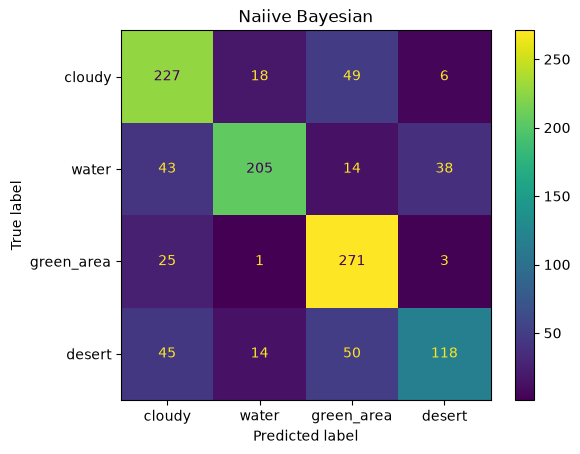

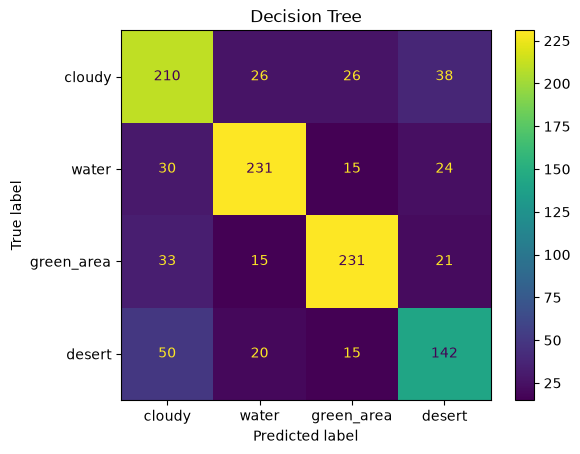

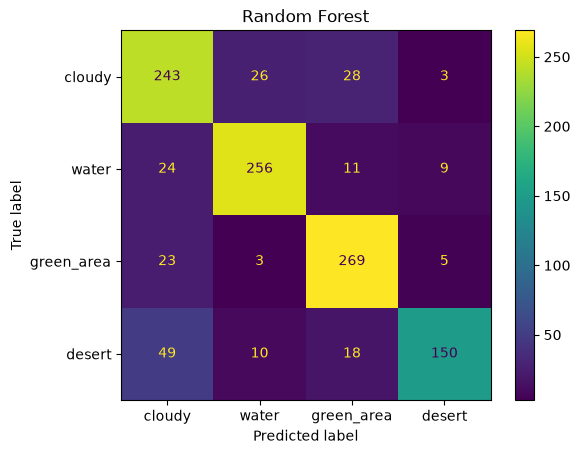

In [3]:
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay

bayesPred = bayes.fit(Xtrain_scaled, Ytrain).predict(Xtest_scaled)
decisionTreePred = decisionTree.fit(Xtrain_scaled, Ytrain).predict(Xtest_scaled)
randomForestPred = randomForest.fit(Xtrain_scaled, Ytrain).predict(Xtest_scaled)

print(f"Bayes accuracy:         {accuracy_score(Ytest, bayesPred)} F-measure: {f1_score(Ytest, bayesPred, average='macro')}")
print(f"Decision Tree accuracy: {accuracy_score(Ytest, decisionTreePred)} F-measure: {f1_score(Ytest, decisionTreePred, average='macro')}")
print(f"Random Forest accuracy: {accuracy_score(Ytest, randomForestPred)} F-measure: {f1_score(Ytest, randomForestPred, average='macro')}")

# Generate and show confusion matrices

for title, classifier in [
    ("Naiive Bayesian", bayes), ("Decision Tree", decisionTree), ("Random Forest", randomForest)]:

    confusionMatrix = ConfusionMatrixDisplay.from_estimator(
        classifier,
        Xtest_scaled,
        Ytest,
        display_labels=classes
    )
    confusionMatrix.ax_.set_title(title)

d) While all three classifiers performed reasonably well, the Naiive Bayes classifier seemed to frequently confuse desert images with green images. This is somewhat understandable as the main feature a human would use to tell these classes apart would be color, which is being discarded here.

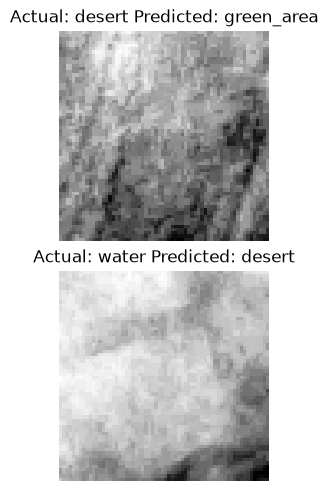

In [18]:
import matplotlib.pyplot as plt

# This code is to find the first two images that were misclassified by the Naiive Bayes classifier

misclassifiedImages = []
for i in range(len(bayesPred)):
    if len(misclassifiedImages) >= 2:
        break

    if bayesPred[i] != Ytest[i]:
        misclassifiedImages.append(i)

if len(misclassifiedImages) == 2:
    
    fig = plt.figure(layout="constrained")
    axes = fig.subplots(2, 1)

    axes[0].imshow(images[misclassifiedImages[0]], cmap='Greys')
    axes[0].set_title(f"Actual: {classes[Ytest[misclassifiedImages[0]]]} Predicted: {classes[bayesPred[misclassifiedImages[0]]]}")
    axes[0].set_axis_off()

    axes[1].imshow(images[misclassifiedImages[1]], cmap='Greys')
    axes[1].set_title(f"Actual: {classes[Ytest[misclassifiedImages[1]]]} Predicted: {classes[bayesPred[misclassifiedImages[1]]]}")
    axes[1].set_axis_off()

plt.show()

e) In the case of the first image, I can imagine that the model may have interpreted those dark streaks across the bottom of the picture as trees. For the second picture, the image is quite bright and features some geometric lines, which are common to see in satellite images of deserts.

3: Model Selection and Model Complexity
---

The two classes I will be using are green area and desert, since those were two classes that the Bayes classifier struggled with.

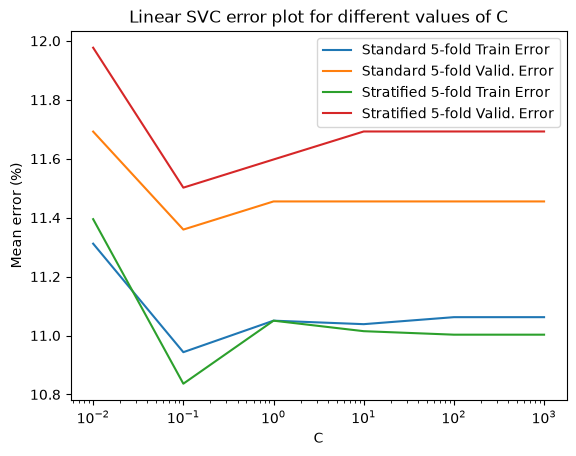

In [19]:
from sklearn.svm import LinearSVC
from sklearn.model_selection import KFold, cross_validate

X2 = []
Y2 = []

for i in range(len(histograms)):
    if image_classes[i] > 1:
        X2.append(histograms[i])
        Y2.append(image_classes[i])

Xtrain2, Xtest2, Ytrain2, Ytest2 = train_test_split(X2, Y2, test_size=0.2, stratify=Y2)

scaler = preprocessing.StandardScaler()
scaler.fit(Xtrain2)

Xtrain2_scaled = scaler.transform(Xtrain2)
Xtest2_scaled = scaler.transform(Xtest2)

cvalues = [0.01, 0.1, 1, 10, 100, 1000]

trainError5Fold = []
validationError5Fold = []
trainError5FoldStratified = []
validationError5FoldStratified = []

for C in cvalues:
    svc = LinearSVC(C=C)

    cvStandard = KFold(n_splits=5)

    scores = cross_validate(svc, Xtrain2_scaled, Ytrain2, cv=cvStandard, scoring='accuracy', return_train_score=True)

    trainError5Fold.append(100 * (1 - np.mean(scores['train_score'])))
    validationError5Fold.append(100 * (1 - np.mean(scores['test_score'])))

    cvStratified = StratifiedKFold(n_splits=5)

    scores = cross_validate(svc, Xtrain2_scaled, Ytrain2, cv=cvStratified, scoring='accuracy', return_train_score=True)

    trainError5FoldStratified.append(100 * (1 - np.mean(scores['train_score'])))
    validationError5FoldStratified.append(100 * (1 - np.mean(scores['test_score'])))

fig, ax = plt.subplots()

ax.set_title("Linear SVC error plot for different values of C")
ax.set_xlabel("C")
ax.set_ylabel("Mean error (%)")
line1 = ax.semilogx(cvalues, trainError5Fold, label="Standard 5-fold Train Error")
line2 = ax.semilogx(cvalues, validationError5Fold, label="Standard 5-fold Valid. Error")
line3 = ax.semilogx(cvalues, trainError5FoldStratified, label="Stratified 5-fold Train Error")
line4 = ax.semilogx(cvalues, validationError5FoldStratified, label="Stratified 5-fold Valid. Error")
ax.legend()

plt.show()

b) C=0.1 gave the lowest mean validation error for all four cross-validation approaches. Increasing the value of C lowers the amount of regularization, which increases the complexity of the model and makes it take longer to train. As seen by the graph, this doesn't actually have a significant effect on the error. Since the training and validation errors are not unacceptably high, underfitting can be ruled out. However, since the validation error is slightly higher than the training error, there may be a little overfitting happening. The standard and stratified cross-validation errors are pretty similar.

In [20]:
# Using C = 0.1

svc = LinearSVC(C=0.1)

svcPred = svc.fit(Xtrain2_scaled, Ytrain2).predict(Xtest2_scaled)

print(f"Test Classification Error: {100 * (1 - accuracy_score(Ytest2, svcPred))}")


Test Classification Error: 13.282732447817835


c) The test classification error is actually closer to the training error from the cross-validation set, and not the validation error. However, all three errors are reasonably close.

4: Final Analysis
---

When it came to classifying all four classes, the random forest classifier performed the best in both the cross-validation and test steps, in both cases having an accuracy exceeding 80%. The Naiive Bayes and decision tree classifiers performed similarly to each other with approximately 70% accuracy. The random forest classifier did sometimes confuse desert images for cloudy ones, as seen by the confusion matrix. The 36-dimensional edge histograms are enough to get decent classification performance, however it still seems likely that an alternative representation that incorporates color information could perform better.